# **Decision Tree and Random Forest** (corrected notebook, Chapter 7)
Changes against `Decision_Tree_and_Random_Forest_original.ipynb`: one-hot encoding instead of arbitrary integer codes; correct class names (0 = malignant, 1 = benign); same criterion for tree and forest; stratified split; repeated splits with mean and standard deviation; train accuracy and tree size; out-of-bag score; correct titles and comments; safe model saving.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

## 1. Decision tree on PlayTennis (14 days)

In [2]:
df = pd.DataFrame({
    "Outlook":  ["Sunny","Sunny","Overcast","Rain","Rain","Rain","Overcast","Sunny","Sunny","Rain","Sunny","Overcast","Overcast","Rain"],
    "Temp":     ["Hot","Hot","Hot","Mild","Cool","Cool","Cool","Mild","Cool","Mild","Mild","Mild","Hot","Mild"],
    "Humidity": ["High","High","High","High","Normal","Normal","Normal","High","Normal","Normal","Normal","High","Normal","High"],
    "Wind":     ["Weak","Strong","Weak","Weak","Weak","Strong","Strong","Weak","Weak","Weak","Strong","Strong","Weak","Strong"],
    "PlayTennis": ["No","No","Yes","Yes","Yes","No","Yes","No","Yes","Yes","Yes","Yes","Yes","No"],
})
y_pt = (df["PlayTennis"] == "Yes").astype(int)          # No = 0, Yes = 1
# One-hot: every question is "is Outlook = Sunny?", not a threshold on arbitrary integer codes
X_pt = pd.get_dummies(df.drop(columns="PlayTennis")).astype(int)
X_pt.head(3)

,Outlook_Overcast,Outlook_Rain,Outlook_Sunny,Temp_Cool,Temp_Hot,Temp_Mild,Humidity_High,Humidity_Normal,Wind_Strong,Wind_Weak
0,0,0,1,0,1,0,1,0,0,1
1,0,0,1,0,1,0,1,0,1,0
2,1,0,0,0,1,0,1,0,0,1


training accuracy: 1.0  depth: 4  leaves: 7
|--- Outlook_Overcast <= 0.50
|   |--- Humidity_Normal <= 0.50
|   |   |--- Outlook_Rain <= 0.50
|   |   |   |--- class: 0
|   |   |--- Outlook_Rain >  0.50
|   |   |   |--- Wind_Strong <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Wind_Strong >  0.50
|   |   |   |   |--- class: 0
|   |--- Humidity_Normal >  0.50
|   |   |--- Wind_Strong <= 0.50
|   |   |   |--- class: 1
|   |   |--- Wind_Strong >  0.50
|   |   |   |--- Outlook_Sunny <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Outlook_Sunny >  0.50
|   |   |   |   |--- class: 1
|--- Outlook_Overcast >  0.50
|   |--- class: 1



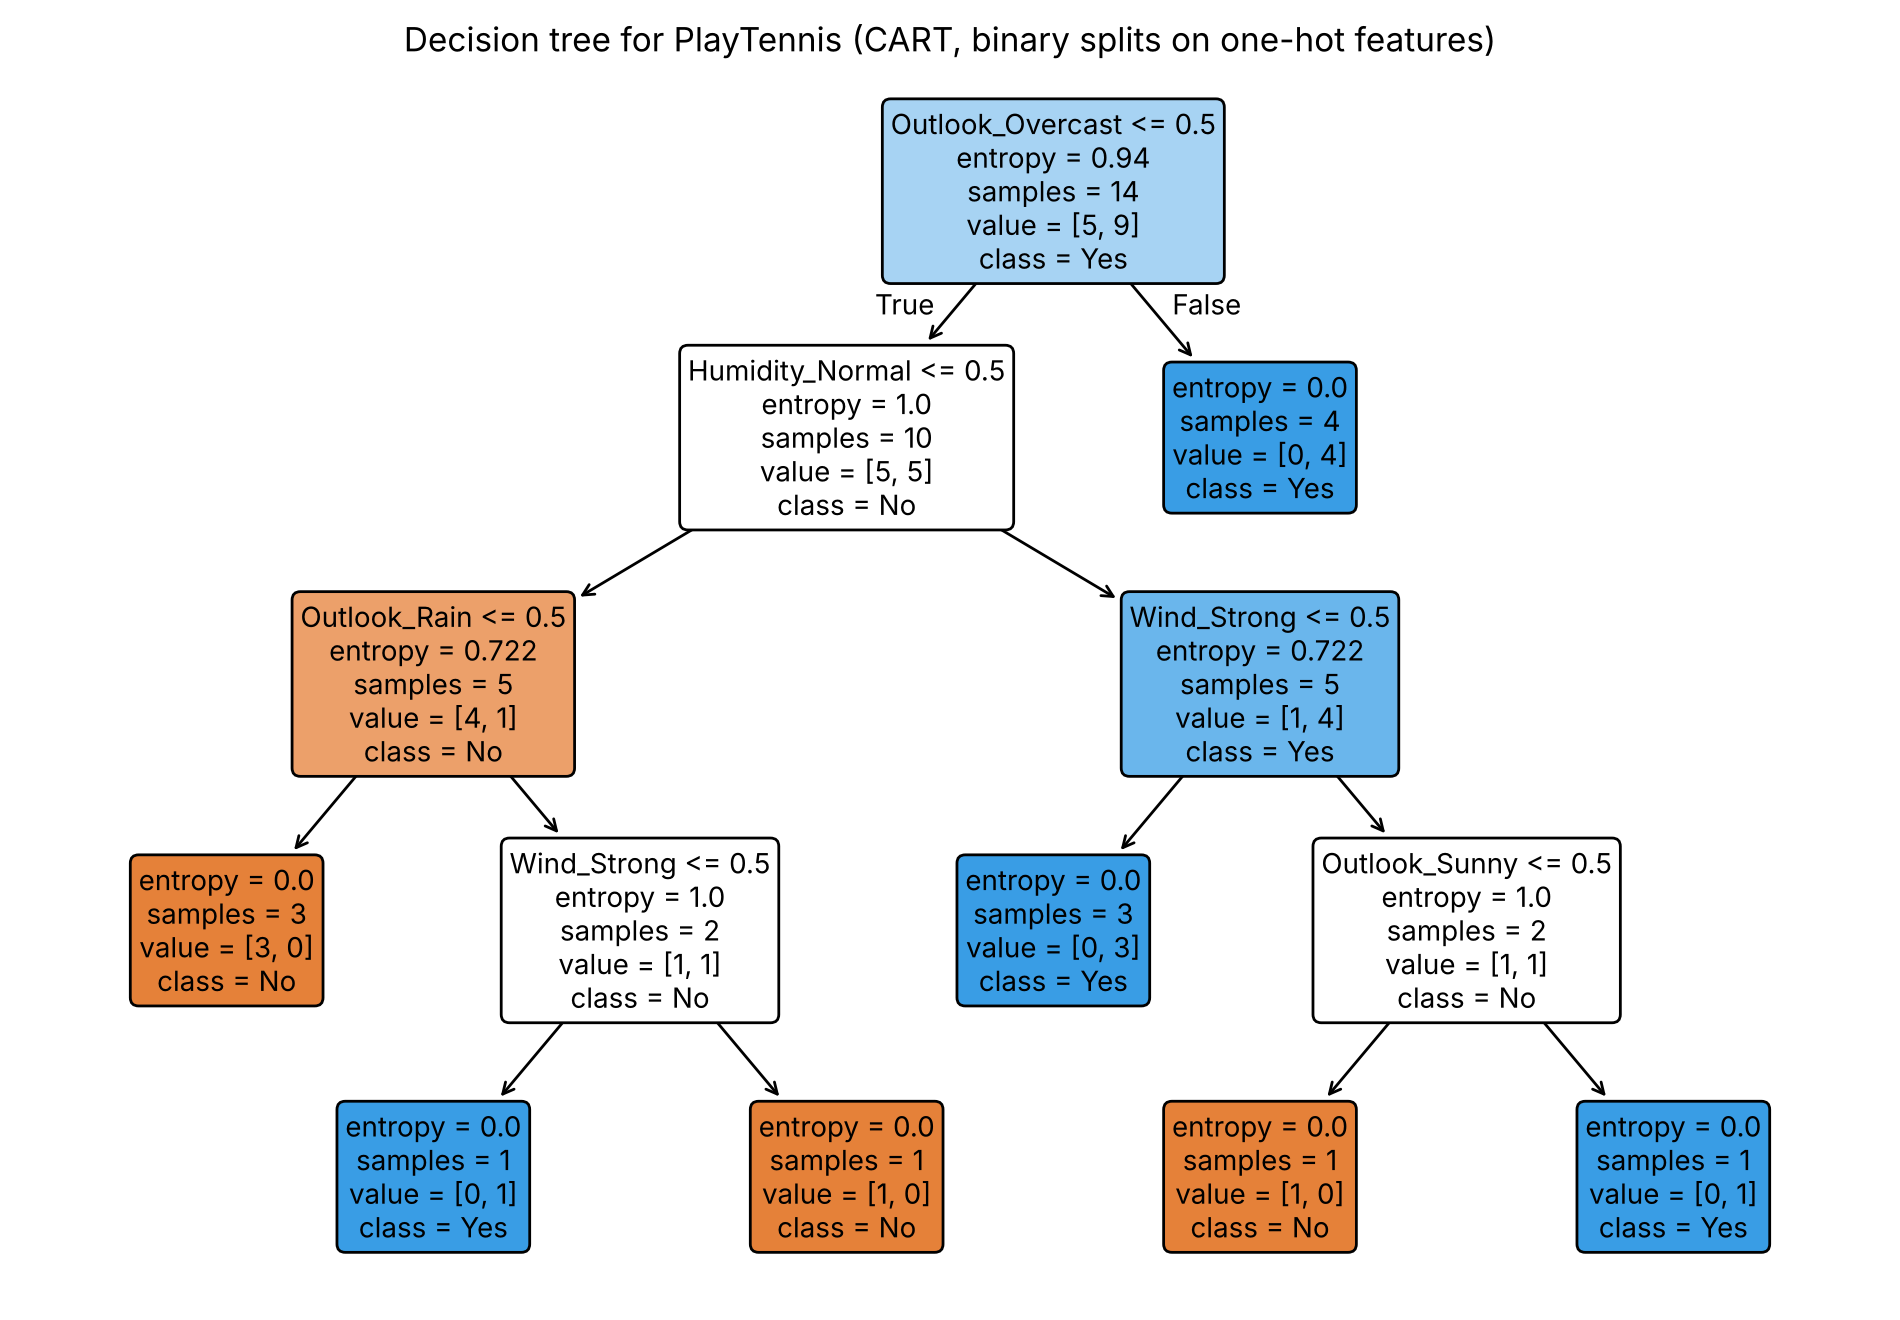

In [3]:
tree_pt = DecisionTreeClassifier(criterion="entropy", random_state=42).fit(X_pt, y_pt)
print("training accuracy:", tree_pt.score(X_pt, y_pt), " depth:", tree_pt.get_depth(), " leaves:", tree_pt.get_n_leaves())
print(export_text(tree_pt, feature_names=list(X_pt.columns)))
plt.figure(figsize=(12, 8))
plot_tree(tree_pt, feature_names=X_pt.columns, class_names=["No", "Yes"], filled=True, rounded=True, fontsize=10)
plt.title("Decision tree for PlayTennis (CART, binary splits on one-hot features)")
plt.show()

scikit-learn builds **binary CART trees**, so this tree is not the multiway ID3 tree of the slides (Outlook with three branches); it classifies all 14 training days correctly because no two days have equal features and different labels.

## 2. Random forest on PlayTennis

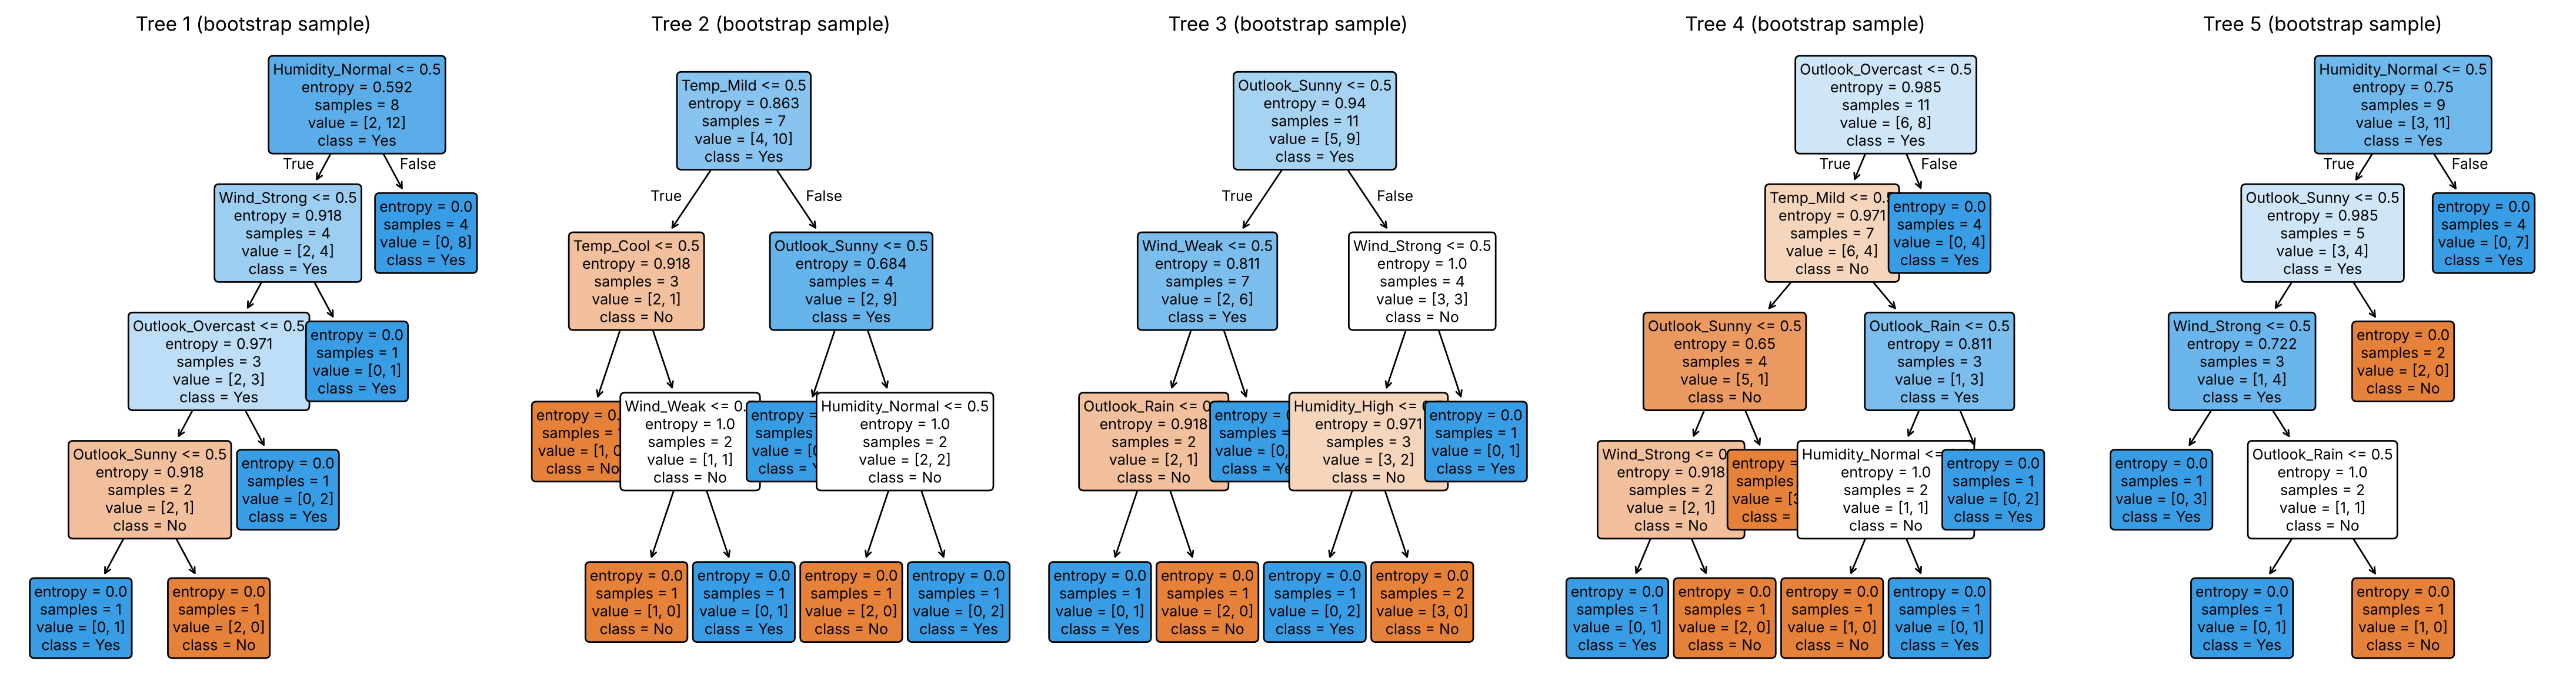

In [4]:
rf_pt = RandomForestClassifier(n_estimators=5, criterion="entropy", random_state=42).fit(X_pt, y_pt)  # 5 trees
fig, axes = plt.subplots(1, 5, figsize=(22, 6))
for i, t in enumerate(rf_pt.estimators_):
    plot_tree(t, feature_names=X_pt.columns, class_names=["No", "Yes"], filled=True, rounded=True, fontsize=9, ax=axes[i])
    axes[i].set_title(f"Tree {i + 1} (bootstrap sample)")
plt.tight_layout(); plt.show()

## 3. Breast cancer data
In `load_breast_cancer` the target is **0 = malignant, 1 = benign**; precision and recall below treat *benign* as the positive class.

In [5]:
data = load_breast_cancer()
X, y = data.X if hasattr(data, "X") else data.data, data.target
print(X.shape, dict(zip(data.target_names, np.bincount(y))))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(569, 30) {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
(455, 30) (114, 30)


In [6]:
def report(model, name):
    p = model.predict(X_test)
    print(f"{name:14s} train {model.score(X_train, y_train):.4f}  test {accuracy_score(y_test, p):.4f}  "
          f"precision {precision_score(y_test, p):.4f}  recall {recall_score(y_test, p):.4f}  F1 {f1_score(y_test, p):.4f}")
    return p

# Same criterion (gini) for both models, so that only 'one tree vs many trees' differs
clf = DecisionTreeClassifier(criterion="gini", random_state=42).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=50, criterion="gini", oob_score=True, random_state=42).fit(X_train, y_train)
p_tree = report(clf, "tree")
p_rf = report(rf, "forest (50)")
print("tree depth", clf.get_depth(), "leaves", clf.get_n_leaves(), "| forest OOB accuracy", round(rf.oob_score_, 4))
print("114 test points: one extra mistake changes accuracy by", round(1 / 114, 4))

tree           train 1.0000  test 0.9123  precision 0.9559  recall 0.9028  F1 0.9286
forest (50)    train 1.0000  test 0.9561  precision 0.9589  recall 0.9722  F1 0.9655
tree depth 7 leaves 19 | forest OOB accuracy 0.9451
114 test points: one extra mistake changes accuracy by 0.0088


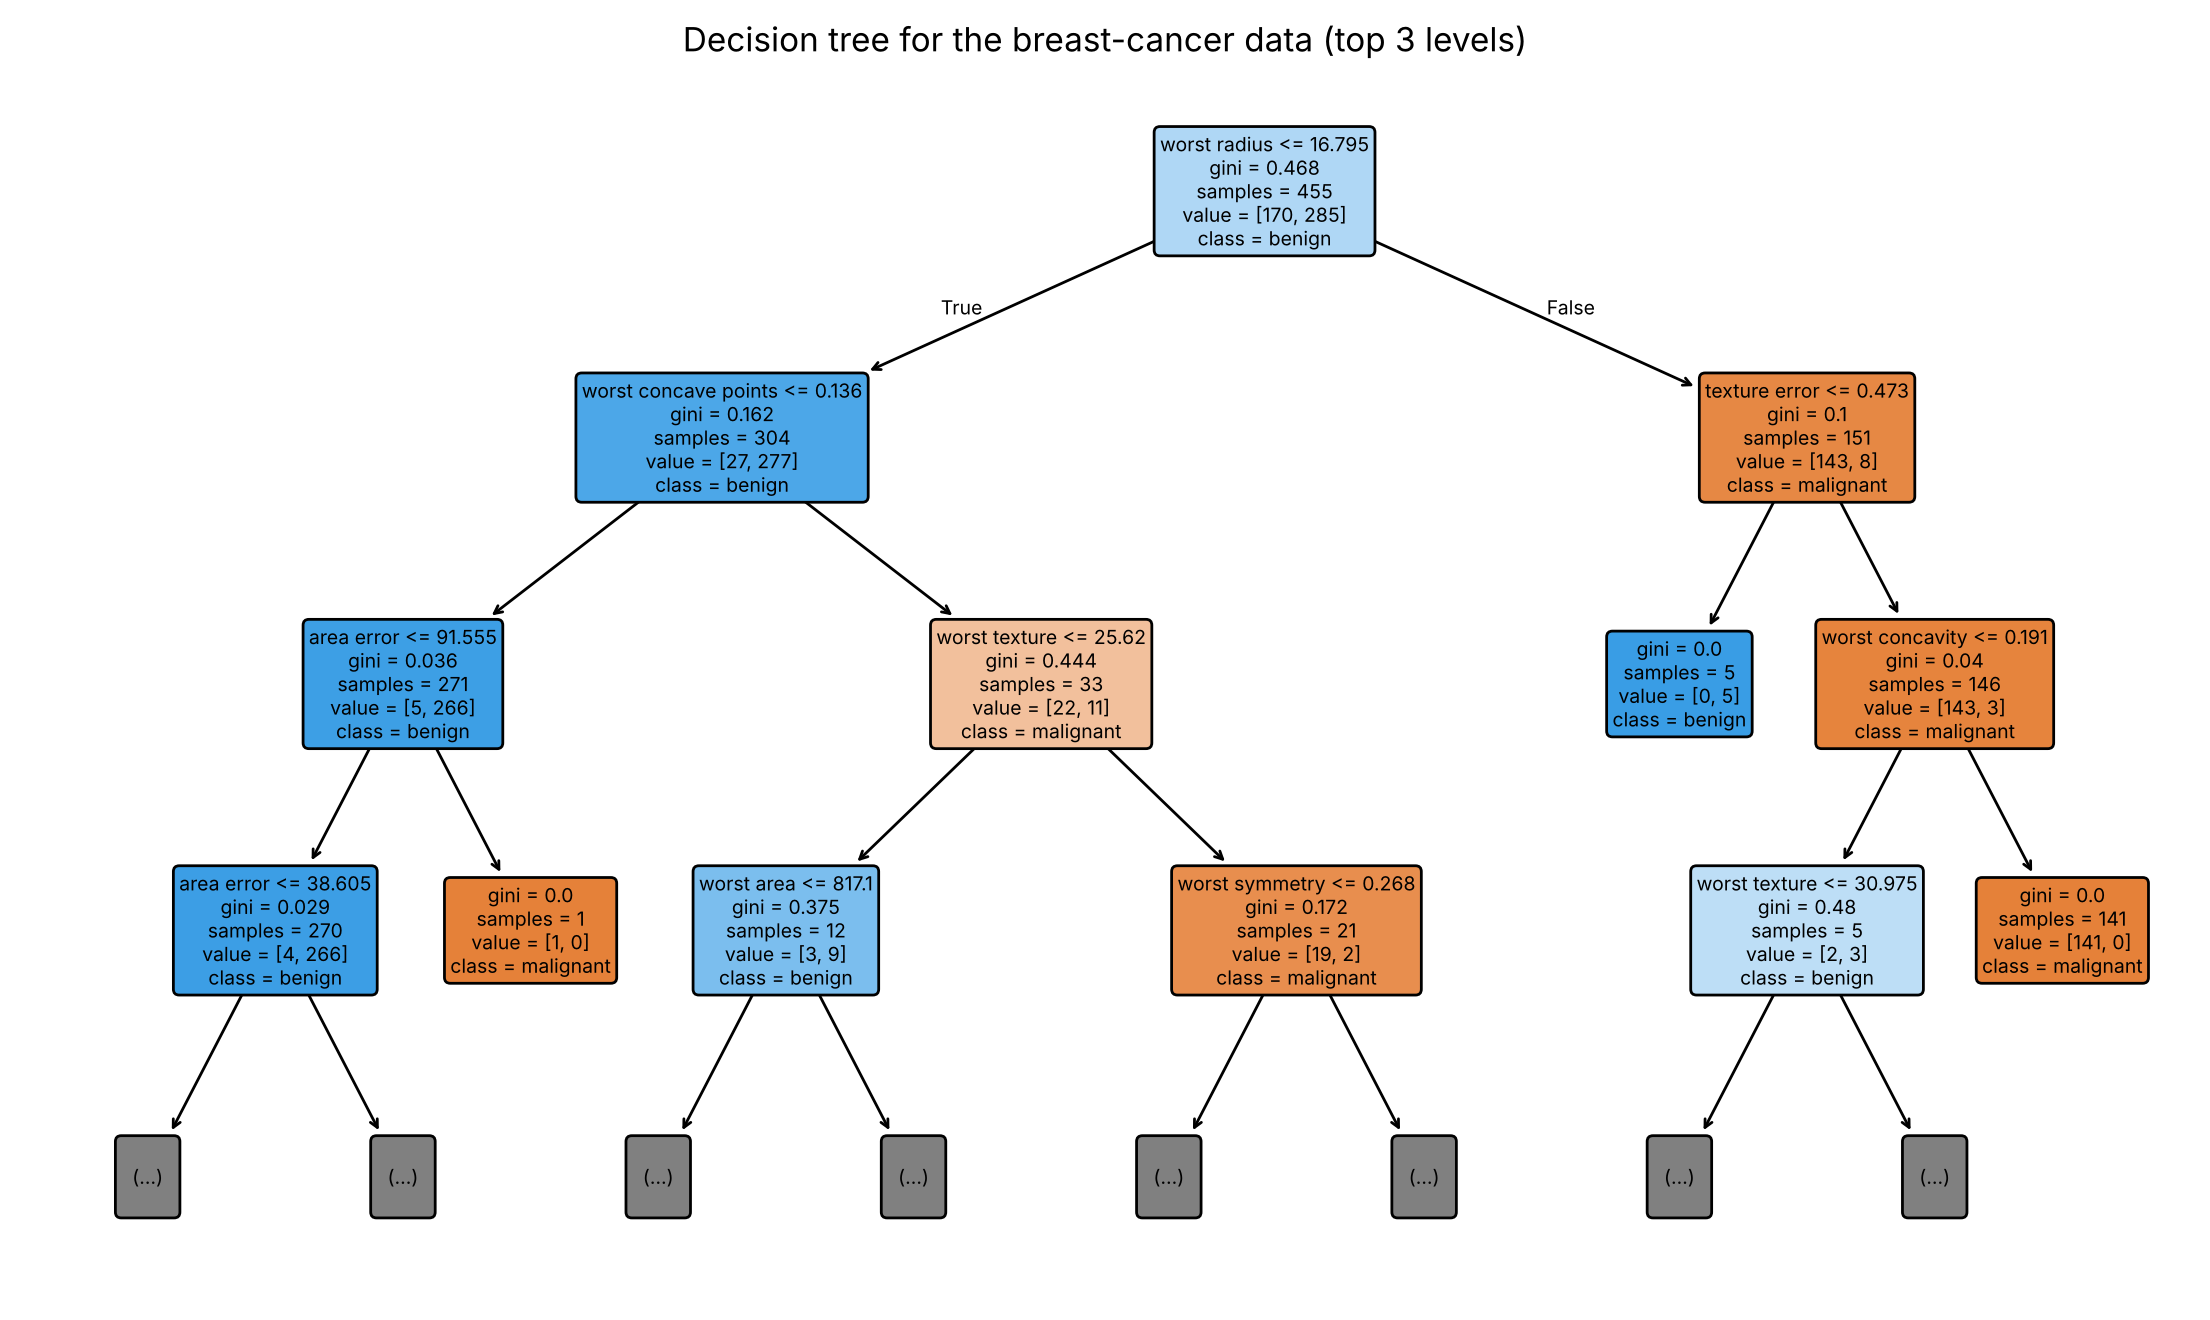

In [7]:
plt.figure(figsize=(14, 8))
plot_tree(clf, feature_names=data.feature_names, class_names=list(data.target_names), filled=True, rounded=True,
          fontsize=7, max_depth=3)
plt.title("Decision tree for the breast-cancer data (top 3 levels)")
plt.show()

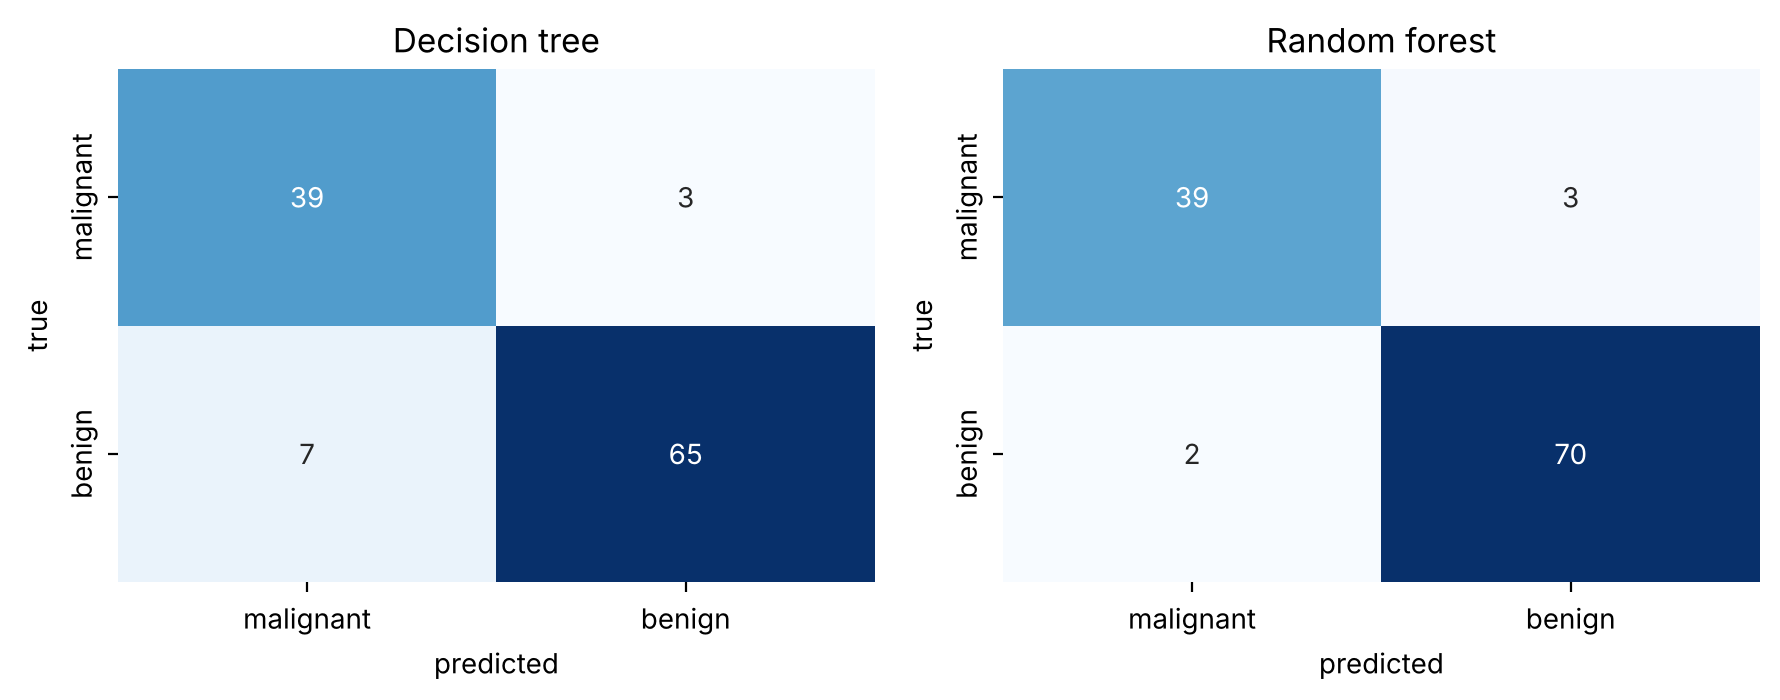

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, p, name in zip(axes, (p_tree, p_rf), ("Decision tree", "Random forest")):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=data.target_names, yticklabels=data.target_names)
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## 4. Is the forest really better? Ten stratified splits
One split of 114 points cannot tell: a single extra error moves the accuracy by 0.9 points.

In [9]:
rows = []
for s in range(10):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    t = DecisionTreeClassifier(criterion="gini", random_state=s).fit(a, c).score(b, d)
    f = RandomForestClassifier(n_estimators=50, criterion="gini", random_state=s).fit(a, c).score(b, d)
    rows.append((t, f))
r = np.array(rows)
print(f"tree   {r[:,0].mean():.3f} +- {r[:,0].std(ddof=1):.3f}")
print(f"forest {r[:,1].mean():.3f} +- {r[:,1].std(ddof=1):.3f}   forest better in {(r[:,1] > r[:,0]).sum()}/10 splits")

tree   0.933 +- 0.029
forest 0.969 +- 0.013   forest better in 8/10 splits


## 5. Feature importance and saving the model

In [10]:
imp = pd.Series(rf.feature_importances_, index=data.feature_names).sort_values(ascending=False)
print(imp.head(5).round(3))
# Impurity-based importances favour high-cardinality/continuous features; see Chapter 7 for permutation importance.

worst concave points    0.129
worst radius            0.114
mean perimeter          0.096
worst area              0.088
mean concave points     0.082
dtype: float64


In [11]:
import joblib
joblib.dump(rf, "random_forest_breast_cancer.pkl")
loaded = joblib.load("random_forest_breast_cancer.pkl")      # only load pickle files that you created yourself!
x0 = X_test[:1]                                              # shape (1, 30)
print("predicted:", data.target_names[loaded.predict(x0)[0]], "| actual:", data.target_names[y_test[0]])

predicted: malignant | actual: malignant
